In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from scipy.stats import linregress
import dask
import cartopy.crs as ccrs, cartopy.feature as cfeature
from matplotlib.patches import Rectangle
import seaborn as sns
from dask_jobqueue import PBSCluster
from dask.distributed import Client
from cartopy.feature import ShapelyFeature
from cartopy.io.shapereader import Reader
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

In [2]:
months = [5,6]
time_slice = slice('1950','2024')

In [3]:
t2_anom = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment/AMJJAS_anom/VAR_2T_ERA5_India_AMJJAS_anom.nc', chunks={'time':-1})
z500_anom = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment/AMJJAS_anom/Z500_ERA5_India_AMJJAS_anom.nc', chunks={'time':-1})
msl_anom = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment/AMJJAS_anom/MSL_ERA5_India_AMJJAS_anom.nc', chunks={'time':-1})
z500_t2 = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment/L1/dyn_adj/Z500_1950/dyn_adj_ERA5_India_50_34_20_74.nc', chunks={'time':-1})
msl_t2 = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment/L1/dyn_adj/MSL_1950/dyn_adj_ERA5_India_50_34_20_74.nc', chunks={'time':-1})

In [4]:
t2_anom = t2_anom.sel(time=t2_anom.time.dt.month.isin(months)).sel(time=time_slice)['anom']
z500_anom = z500_anom.sel(time=z500_anom.time.dt.month.isin(months)).sel(time=time_slice)['anom']
msl_anom = msl_anom.sel(time=msl_anom.time.dt.month.isin(months)).sel(time=time_slice)['anom']
z500_t2 = z500_t2.sel(time=z500_t2.time.dt.month.isin(months)).sel(time=time_slice)['dynamic']
msl_t2 = msl_t2.sel(time=msl_t2.time.dt.month.isin(months)).sel(time=time_slice)['dynamic']

/glade/work/adixit/conda-envs/dask/lib/python3.10/site-packages/xarray/core/indexing.py:1620: PerformanceWarning: Slicing is producing a large chunk. To accept the large
chunk and silence this warning, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': False}):
    ...     array[indexer]

To avoid creating the large chunks, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    ...     array[indexer]
  return self.array[key]


In [5]:
z500_t2_anom_corr = xr.corr(z500_anom,t2_anom,dim='time')
z500_t2_da_corr = xr.corr(z500_anom,z500_t2,dim='time')
msl_t2_anom_corr = xr.corr(msl_anom,t2_anom,dim='time')
msl_t2_da_corr = xr.corr(msl_anom,msl_t2,dim='time')

z500_t2_anom_corr = dask.compute(z500_t2_anom_corr)[0]
z500_t2_da_corr = dask.compute(z500_t2_da_corr)[0]
msl_t2_anom_corr = dask.compute(msl_t2_anom_corr)[0]
msl_t2_da_corr = dask.compute(msl_t2_da_corr)[0]

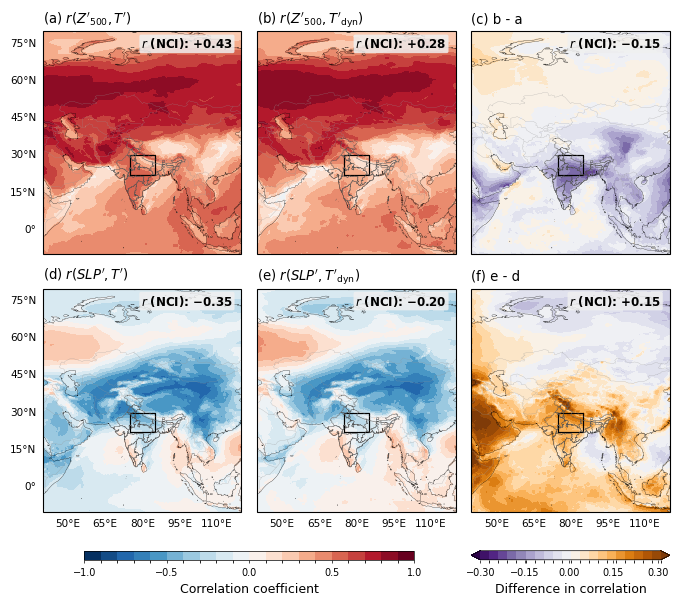

In [7]:
shp_file = '/glade/derecho/scratch/adixit/India_Heatwave/shapefiles/india_st.shp'
shape_feature = ShapelyFeature(Reader(shp_file).geometries(), ccrs.PlateCarree(),facecolor='none')
box = dict(lat=slice(30, 22), lon=slice(75, 85)) 

def box_mean(da):
    b = da.sel(**box)
    return b.mean(dim=["lat", "lon"])

PC = ccrs.PlateCarree()
data = [[z500_t2_anom_corr,z500_t2_da_corr,z500_t2_da_corr-z500_t2_anom_corr],[msl_t2_anom_corr,msl_t2_da_corr,msl_t2_da_corr-msl_t2_anom_corr]]
cols  = ["T2m anomaly", "T2m dynamic adjustment", "Difference (anomaly − dynamic adj.)"]
rows  = ["Z500", "SLP"]
lev_c, lev_d = np.linspace(-1, 1, 21), np.linspace(-0.30, 0.31, 21)
levs = [[lev_c, lev_c, lev_d],[lev_c, lev_c, lev_d]]
cmaps = [["RdBu_r","RdBu_r","PuOr_r"],["RdBu_r","RdBu_r","PuOr_r"]]
extnds = [['neither','neither','both'],['neither','neither','both']]
pcs = []
titles = [[r"(a) $\mathit{r} (Z'_{500}, T')$", r"(b) $\mathit{r} (Z'_{500}, T'_{\mathrm{dyn}})$", r"(c) b - a",],
          [r"(d) $\mathit{r} (SLP', T')$", r"(e) $\mathit{r} (SLP', T'_{\mathrm{dyn}})$", r"(f) e - d",]]

fig = plt.figure(figsize=(7,7))
gs = fig.add_gridspec(3, 3, height_ratios=[1, 1, 0.07], left=0.09, right=0.985, top=0.94, hspace=0.2, wspace=0.08)
anchors = [["SE", "S", "SW"],
           ["NE", "N", "NW"]]
for i in range(2):
    for j in range(3):
        ax = fig.add_subplot(gs[i, j], projection=PC)
        ax.set_anchor(anchors[i][j])
        ax.coastlines(resolution='50m', linewidth=0.2, color='black')
        ax.add_feature(shape_feature, edgecolor='#525252', lw=0.25,zorder=52)
        ax.add_feature(cfeature.BORDERS, edgecolor='#969696',lw=0.15)
        da = data[i][j]
        pc = da.plot.contourf(ax=ax, transform=PC, levels=levs[i][j], cmap=cmaps[i][j], add_colorbar=False,extend=extnds[i][j])
        pcs.append(pc)
        ax.add_patch(Rectangle((75, 22), 10, 8, fill=False, ec="#000000", lw=0.8, transform=PC))
        ax.set_title("" if i == 0 else "", fontsize=0)
        ax.set_title(titles[i][j], fontsize=9.5, loc='left')
        gl = ax.gridlines(draw_labels=True, lw=0)
        gl.xlocator = mpl.ticker.FixedLocator(range(20, 121, 15))
        gl.ylocator = mpl.ticker.FixedLocator(range(0, 90, 15))
        gl.top_labels = gl.right_labels = False
        gl.bottom_labels, gl.left_labels = (i == 1), (j == 0)
        gl.xlabel_style = gl.ylabel_style = {"size": 7.5}

        ax.add_patch(Rectangle((75, 22), 10, 8, fill=False, ec="k", lw=0.8, transform=PC))
        ax.text(98, 78, f"$r$ (NCI): {box_mean(da):+.2f}".replace("-", "−"), transform=PC,
                ha="center", va="top", fontsize=8.5, fontweight="bold",bbox=dict(boxstyle="round,pad=0.15", fc="#f0f0f0", ec="none", alpha=0.85))
        
for pc, cells, ticks, label, width in [
    (pcs[0], slice(0, 2), [-1, -.5, 0, .5, 1], "Correlation coefficient", .8),
    (pcs[2], 2, [-.3, -.15, 0, .15, .3], "Difference in correlation", 1)
]:
    b = gs[2, cells].get_position(fig)
    w = b.width * width
    cax = fig.add_axes([b.x0 + (b.width-w)/2, b.y0 + .04, w, .013])
    cb = fig.colorbar(pc, cax=cax, orientation="horizontal", ticks=ticks)
    cb.set_label(label, fontsize=9, labelpad=4)
    cb.ax.tick_params(labelsize=7, length=2, width=.5)
    cb.outline.set_linewidth(.5)
mpl.rcParams['pdf.fonttype'] = 3
plt.savefig("ERA5-thermalLow_verify_warming.pdf",format='pdf',transparent=True)

## For unforced ERA5 runs

In [11]:
months = [5,6]
time_slice = slice('1950','2024')

In [12]:
t2_anom = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment_unforced_smooth/AMJJAS_anom/VAR_2T_ERA5_India_AMJJAS_anom.nc', chunks={'time':-1})
z500_anom = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment_unforced_smooth_Z500/AMJJAS_anom/Z500_ERA5_India_AMJJAS_anom.nc', chunks={'time':-1})
msl_anom = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment_unforced_smooth/AMJJAS_anom/MSL_ERA5_India_AMJJAS_anom.nc', chunks={'time':-1})
z500_t2 = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment_unforced_smooth_Z500/L1/dyn_adj/dyn_adj_ERA5_India_50_34_20_74.nc', chunks={'time':-1})
msl_t2 = xr.open_mfdataset('/glade/derecho/scratch/adixit/India_Heatwave/dynamic_adjustment_unforced_smooth/L1/dyn_adj/dyn_adj_ERA5_India_50_34_20_74.nc', chunks={'time':-1})

In [13]:
t2_anom = t2_anom.sel(time=t2_anom.time.dt.month.isin(months)).sel(time=time_slice)['anom']
z500_anom = z500_anom.sel(time=z500_anom.time.dt.month.isin(months)).sel(time=time_slice)['anom']
msl_anom = msl_anom.sel(time=msl_anom.time.dt.month.isin(months)).sel(time=time_slice)['anom']
z500_t2 = z500_t2.sel(time=z500_t2.time.dt.month.isin(months)).sel(time=time_slice)['dynamic']
msl_t2 = msl_t2.sel(time=msl_t2.time.dt.month.isin(months)).sel(time=time_slice)['dynamic']

/glade/work/adixit/conda-envs/dask/lib/python3.10/site-packages/xarray/core/indexing.py:1620: PerformanceWarning: Slicing is producing a large chunk. To accept the large
chunk and silence this warning, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': False}):
    ...     array[indexer]

To avoid creating the large chunks, set the option
    >>> with dask.config.set(**{'array.slicing.split_large_chunks': True}):
    ...     array[indexer]
  return self.array[key]


In [14]:
z500_t2_anom_corr = xr.corr(z500_anom,t2_anom,dim='time')
z500_t2_da_corr = xr.corr(z500_anom,z500_t2,dim='time')
msl_t2_anom_corr = xr.corr(msl_anom,t2_anom,dim='time')
msl_t2_da_corr = xr.corr(msl_anom,msl_t2,dim='time')

In [15]:
z500_t2_anom_corr = dask.compute(z500_t2_anom_corr)[0]
z500_t2_da_corr = dask.compute(z500_t2_da_corr)[0]
msl_t2_anom_corr = dask.compute(msl_t2_anom_corr)[0]
msl_t2_da_corr = dask.compute(msl_t2_da_corr)[0]

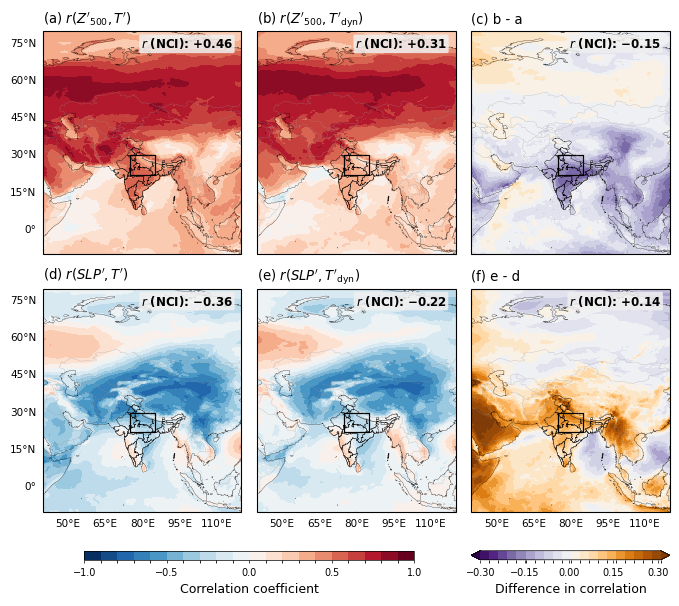

In [16]:
shp_file = '/glade/derecho/scratch/adixit/India_Heatwave/shapefiles/india_st.shp'
shape_feature = ShapelyFeature(Reader(shp_file).geometries(), ccrs.PlateCarree(),edgecolor='black', facecolor='none',lw=0.5)
box = dict(lat=slice(30, 22), lon=slice(75, 85)) 

def box_mean(da):
    b = da.sel(**box)
    return b.mean(dim=["lat", "lon"])

PC = ccrs.PlateCarree()
data = [[z500_t2_anom_corr,z500_t2_da_corr,z500_t2_da_corr-z500_t2_anom_corr],[msl_t2_anom_corr,msl_t2_da_corr,msl_t2_da_corr-msl_t2_anom_corr]]
cols  = ["T2m anomaly", "T2m dynamic adjustment", "Difference (anomaly − dynamic adj.)"]
rows  = ["Z500", "SLP"]
lev_c, lev_d = np.linspace(-1, 1, 21), np.linspace(-0.30, 0.31, 21)
levs = [[lev_c, lev_c, lev_d],[lev_c, lev_c, lev_d]]
cmaps = [["RdBu_r","RdBu_r","PuOr_r"],["RdBu_r","RdBu_r","PuOr_r"]]
extnds = [['neither','neither','both'],['neither','neither','both']]
pcs = []
titles = [[r"(a) $\mathit{r} (Z'_{500}, T')$", r"(b) $\mathit{r} (Z'_{500}, T'_{\mathrm{dyn}})$", r"(c) b - a",],
          [r"(d) $\mathit{r} (SLP', T')$", r"(e) $\mathit{r} (SLP', T'_{\mathrm{dyn}})$", r"(f) e - d",]]

fig = plt.figure(figsize=(7,7))
gs = fig.add_gridspec(3, 3, height_ratios=[1, 1, 0.07], left=0.09, right=0.985, top=0.94, hspace=0.2, wspace=0.08)
anchors = [["SE", "S", "SW"],
           ["NE", "N", "NW"]]
for i in range(2):
    for j in range(3):
        ax = fig.add_subplot(gs[i, j], projection=PC)
        ax.set_anchor(anchors[i][j])
        ax.coastlines(resolution='50m', linewidth=0.2, color='black')
        ax.add_feature(shape_feature, edgecolor='#000000', lw=0.25,zorder=52)
        ax.add_feature(cfeature.BORDERS, edgecolor='#969696',lw=0.15)
        da = data[i][j]
        pc = da.plot.contourf(ax=ax, transform=PC, levels=levs[i][j], cmap=cmaps[i][j], add_colorbar=False,extend=extnds[i][j])
        pcs.append(pc)
        ax.add_patch(Rectangle((75, 22), 10, 8, fill=False, ec="k", lw=0.8, transform=PC))
        ax.set_title("" if i == 0 else "", fontsize=0)
        ax.set_title(titles[i][j], fontsize=9.5, loc='left')
        gl = ax.gridlines(draw_labels=True, lw=0)
        gl.xlocator = mpl.ticker.FixedLocator(range(20, 121, 15))
        gl.ylocator = mpl.ticker.FixedLocator(range(0, 90, 15))
        gl.top_labels = gl.right_labels = False
        gl.bottom_labels, gl.left_labels = (i == 1), (j == 0)
        gl.xlabel_style = gl.ylabel_style = {"size": 7.5}

        ax.add_patch(Rectangle((75, 22), 10, 8, fill=False, ec="k", lw=0.8, transform=PC))
        ax.text(98, 78, f"$r$ (NCI): {box_mean(da):+.2f}".replace("-", "−"), transform=PC,
                ha="center", va="top", fontsize=8.5, fontweight="bold",bbox=dict(boxstyle="round,pad=0.15", fc="#f0f0f0", ec="none", alpha=0.85))
        
for pc, cells, ticks, label, width in [
    (pcs[0], slice(0, 2), [-1, -.5, 0, .5, 1], "Correlation coefficient", .8),
    (pcs[2], 2, [-.3, -.15, 0, .15, .3], "Difference in correlation", 1)
]:
    b = gs[2, cells].get_position(fig)
    w = b.width * width
    cax = fig.add_axes([b.x0 + (b.width-w)/2, b.y0 + .04, w, .013])
    cb = fig.colorbar(pc, cax=cax, orientation="horizontal", ticks=ticks)
    cb.set_label(label, fontsize=9, labelpad=4)
    cb.ax.tick_params(labelsize=7, length=2, width=.5)
    cb.outline.set_linewidth(.5)
mpl.rcParams['pdf.fonttype'] = 3
plt.savefig("Unforced-ERA5-thermalLow_verify_warming.pdf",dpi=300,format='pdf',transparent=True)